# Step 4 — Full First-Fit vs Genetic Algorithm Comparison

This notebook presents the **measured Step 4 results from all 10,000 Step 2 scenarios**. First, run `python src/compare_baseline.py` from the repository root. That reproducible script compares both methods on the same scenarios, room inventory and constraints, and writes the evidence CSVs and chart.

To avoid running the full Genetic Algorithm a second time, this notebook loads and verifies those saved outputs, then displays the results. After changing the script or dataset, rerun the script before rerunning this notebook.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
while not (ROOT / "src" / "compare_baseline.py").is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "compare_baseline.py").is_file():
    raise FileNotFoundError("Open the Time-Table-Optimizer repository folder in VS Code.")

REPORT_DIR = ROOT / "data" / "reports"
METRICS_PATH = REPORT_DIR / "step4_baseline_metrics.csv"
COMPARISON_PATH = REPORT_DIR / "step4_comparison.csv"
PAIRED_PATH = REPORT_DIR / "step4_paired_scenario_results.csv"
CHART_PATH = ROOT / "results" / "step4_baseline_vs_ga.png"

missing = [str(path.relative_to(ROOT)) for path in [METRICS_PATH, COMPARISON_PATH, PAIRED_PATH, CHART_PATH] if not path.is_file()]
if missing:
    raise FileNotFoundError("Run python src/compare_baseline.py first. Missing: " + ", ".join(missing))

metrics = pd.read_csv(METRICS_PATH)
comparison = pd.read_csv(COMPARISON_PATH)
paired = pd.read_csv(PAIRED_PATH)
print("Step 4 output files loaded successfully.")
print("Metrics rows:", len(metrics), "| Comparison rows:", len(comparison), "| Paired scenario rows:", len(paired))

Step 4 output files loaded successfully.
Metrics rows: 8 | Comparison rows: 24 | Paired scenario rows: 10000


## Fairness checks

The Step 2 benchmark has 7,000 normal, 2,000 boundary, and 1,000 stress scenarios. Every scenario must have one paired row containing results from both methods. The first-fit totals must also match the accepted Step 3 baseline.

In [2]:
EXPECTED_BASELINE = {
    "requested_sessions": 125_109,
    "scheduled_sessions": 84_845,
    "unplaced_sessions": 40_264,
    "preference_penalties": 76_364,
    "hard_violations": 0,
}

category_counts = paired[["scenario_id", "case_type"]].drop_duplicates()["case_type"].value_counts().to_dict()
assert len(paired) == 10_000, f"Expected 10,000 paired scenarios, got {len(paired)}"
assert paired["scenario_id"].nunique() == 10_000, "Scenario IDs are missing or duplicated"
assert paired.groupby("scenario_id")["case_type"].nunique().max() == 1, "A scenario ID appears across categories"
assert category_counts == {"normal": 7_000, "boundary": 2_000, "stress": 1_000}, category_counts
assert (paired["baseline_requested_sessions"] == paired["ga_requested_sessions"]).all(), "Methods did not receive identical requests"
assert (paired["baseline_hard_violations"] == 0).all(), "First-fit has a hard violation"
assert (paired["ga_hard_violations"] == 0).all(), "GA has a hard violation"

overall = metrics[metrics["case_type"] == "overall"].set_index("method")
base = overall.loc["First-fit baseline"]
for name, expected in EXPECTED_BASELINE.items():
    actual = int(base[name])
    assert actual == expected, f"Step 3 baseline check failed for {name}: {actual} != {expected}"

checks = pd.DataFrame([
    {"check": "All fixed scenarios included", "result": f"{paired['scenario_id'].nunique():,} / 10,000"},
    {"check": "Category split", "result": f"normal {category_counts['normal']:,}; boundary {category_counts['boundary']:,}; stress {category_counts['stress']:,}"},
    {"check": "Same requested sessions for both methods", "result": "PASS"},
    {"check": "First-fit hard violations", "result": str(int(paired["baseline_hard_violations"].sum()))},
    {"check": "GA hard violations", "result": str(int(paired["ga_hard_violations"].sum()))},
    {"check": "Accepted Step 3 totals match", "result": "PASS"},
])
display(checks)
print("All fair-comparison checks passed.")

,check,result
0,All fixed scenarios included,"10,000 / 10,000"
1,Category split,"normal 7,000; boundary 2,000; stress 1,000"
2,Same requested sessions for both methods,PASS
3,First-fit hard violations,0
4,GA hard violations,0
5,Accepted Step 3 totals match,PASS


All fair-comparison checks passed.


## Results by scenario group

Coverage is the share of requested sessions that were placed. Fewer unplaced sessions and soft preference penalties are better. Hard violations must stay at zero.

In [3]:
display(metrics)
print("Overall GA minus first-fit differences:")
display(comparison[comparison["case_type"] == "overall"])

,case_type,method,scenarios,requested_sessions,scheduled_sessions,unplaced_sessions,mean_coverage_pct,mean_unplaced_sessions_per_scenario,preference_penalties,hard_violations,feasible_scenarios,feasibility_rate_pct,room_slot_utilization_pct_mean
0,overall,First-fit baseline,10000,125109,84845,40264,74.05,4.03,76364,0,2593,25.93,42.50
1,overall,Genetic Algorithm,10000,125109,89381,35728,77.17,3.57,55375,0,2644,26.44,43.19
2,normal,First-fit baseline,7000,70118,58451,11667,84.78,1.67,52640,0,2583,36.90,41.00
3,normal,Genetic Algorithm,7000,70118,60206,9912,87.00,1.42,35305,0,2634,37.63,41.19
4,boundary,First-fit baseline,2000,34991,20494,14497,58.76,7.25,18462,0,10,0.50,49.30
5,boundary,Genetic Algorithm,2000,34991,23033,11958,65.98,5.98,16147,0,10,0.50,51.28
6,stress,First-fit baseline,1000,20000,5900,14100,29.50,14.10,5262,0,0,0.00,39.33
7,stress,Genetic Algorithm,1000,20000,6142,13858,30.71,13.86,3923,0,0,0.00,40.94


Overall GA minus first-fit differences:


,case_type,measure,first_fit_baseline,genetic_algorithm,ga_minus_baseline,interpretation_direction
0,overall,mean_coverage_pct,74.05,77.17,3.12,higher is better
1,overall,mean_unplaced_sessions_per_scenario,4.03,3.57,-0.46,lower is better
2,overall,preference_penalties,76364.00,55375.00,-20989.00,lower is better
3,overall,hard_violations,0.00,0.00,0.00,must remain zero
4,overall,feasibility_rate_pct,25.93,26.44,0.51,higher is better
5,overall,room_slot_utilization_pct_mean,42.50,43.19,0.69,interpret with coverage and unplaced sessions


## Comparison figure

This chart is generated from the measured full-benchmark CSV results.

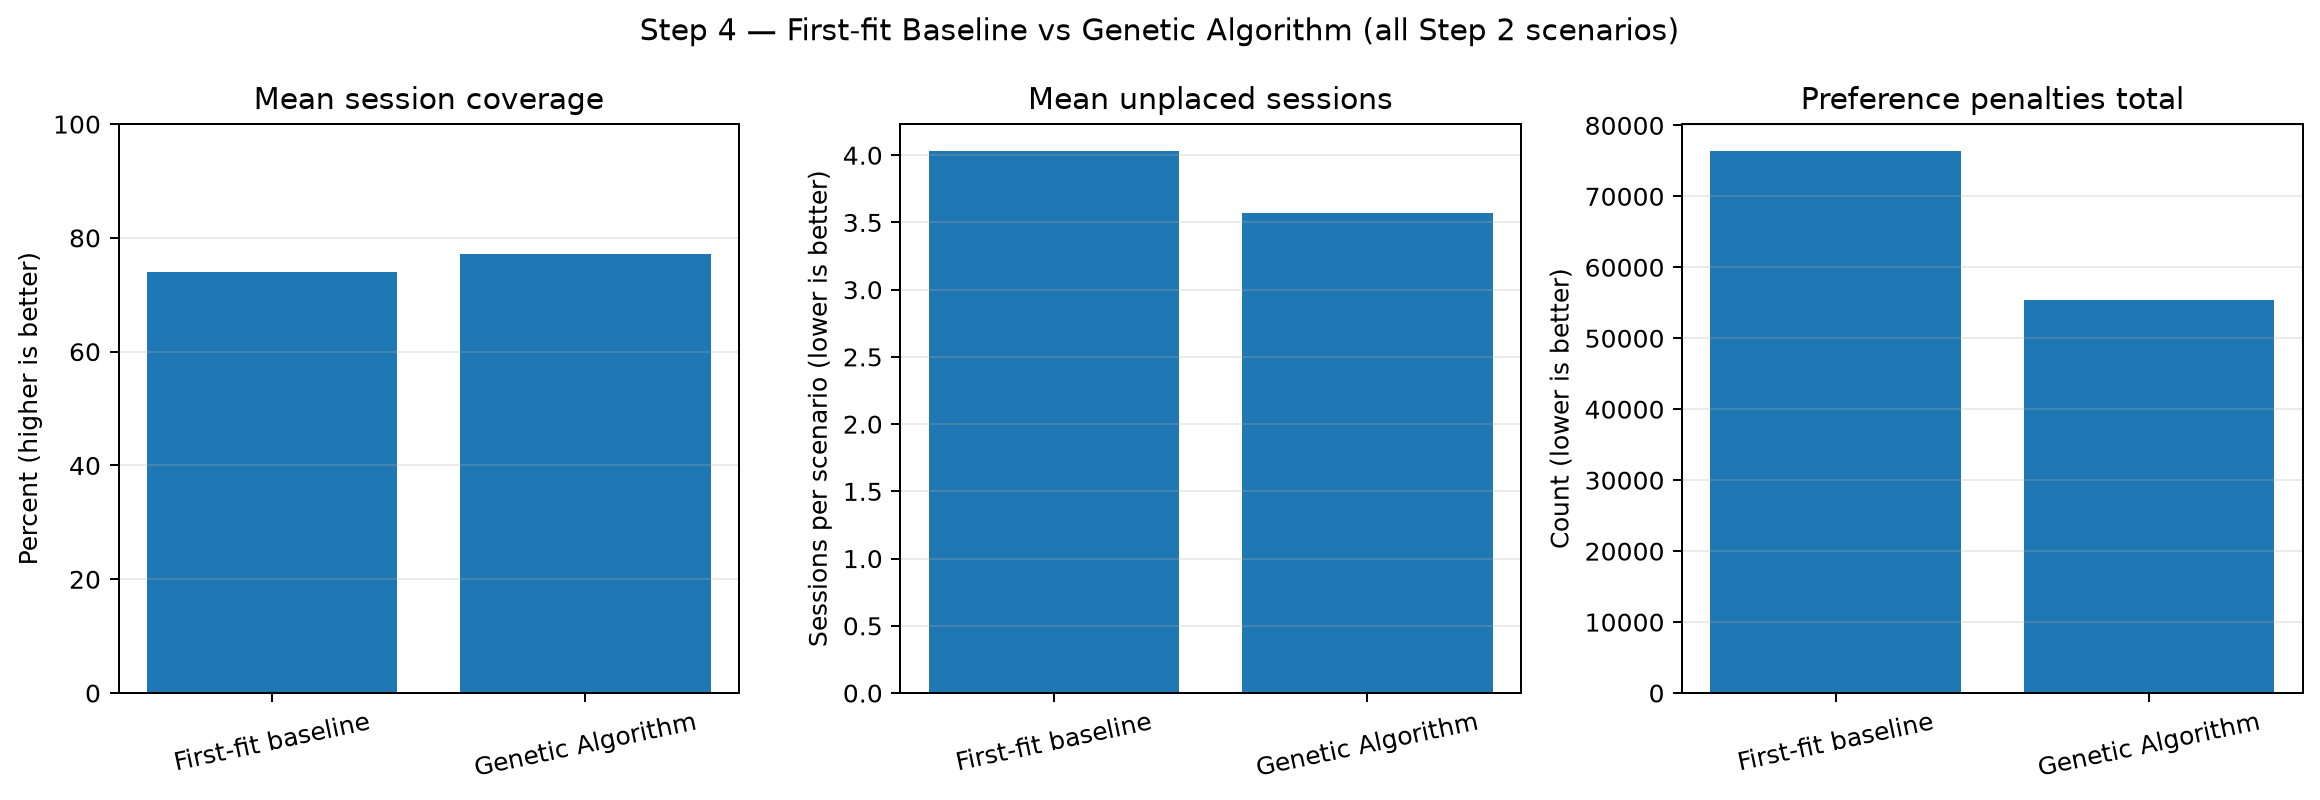

In [4]:
display(Image(filename=str(CHART_PATH)))

## Paired scenario outcomes

Each row below is one scenario ID and includes both methods' results for the same requests. The full 10,000-row file is saved at `data/reports/step4_paired_scenario_results.csv`.

In [5]:
columns_to_show = [
    "scenario_id", "case_type", "baseline_requested_sessions", "baseline_scheduled_sessions",
    "baseline_unplaced_sessions", "baseline_preference_penalties", "baseline_hard_violations",
    "ga_scheduled_sessions", "ga_unplaced_sessions", "ga_preference_penalties", "ga_hard_violations",
]
display(paired[columns_to_show].head(10))
print("Paired scenario rows in saved evidence:", f"{len(paired):,}")

,scenario_id,case_type,baseline_requested_sessions,baseline_scheduled_sessions,baseline_unplaced_sessions,baseline_preference_penalties,baseline_hard_violations,ga_scheduled_sessions,ga_unplaced_sessions,ga_preference_penalties,ga_hard_violations
0,TTO-00001,normal,15,7,8,7,0,9,6,6,0
1,TTO-00002,normal,15,7,8,6,0,8,7,5,0
2,TTO-00003,normal,15,12,3,9,0,11,4,7,0
3,TTO-00004,normal,15,7,8,6,0,9,6,6,0
4,TTO-00005,normal,15,13,2,12,0,13,2,8,0
5,TTO-00006,normal,15,11,4,9,0,11,4,8,0
6,TTO-00007,normal,15,12,3,10,0,12,3,8,0
7,TTO-00008,normal,15,15,0,10,0,15,0,10,0
8,TTO-00009,normal,15,12,3,11,0,14,1,12,0
9,TTO-00010,normal,15,11,4,10,0,14,1,11,0


Paired scenario rows in saved evidence: 10,000


## Interpretation of the measured run

The GA schedules more sessions and reduces soft penalties on this simulated benchmark, while both methods preserve zero hard clashes. Some sessions remain unplaced; this does not prove they are inherently infeasible, because the decoder and finite GA search may fail to find a better valid order. Complete the team-contributions section in `docs/STEP-4.md` with the team's real work before submission.

In [6]:
ga = overall.loc["Genetic Algorithm"]
print(f"Sessions scheduled: {int(ga['scheduled_sessions'] - base['scheduled_sessions']):,} more with GA")
print(f"Session coverage: {base['mean_coverage_pct']:.2f}% -> {ga['mean_coverage_pct']:.2f}% (+{ga['mean_coverage_pct'] - base['mean_coverage_pct']:.2f} percentage points)")
print(f"Unplaced sessions: {int(base['unplaced_sessions']):,} -> {int(ga['unplaced_sessions']):,}")
print(f"Soft preference penalties: {int(base['preference_penalties']):,} -> {int(ga['preference_penalties']):,}")
print(f"Hard violations: first-fit={int(base['hard_violations'])}, GA={int(ga['hard_violations'])}")

Sessions scheduled: 4,536 more with GA
Session coverage: 74.05% -> 77.17% (+3.12 percentage points)
Unplaced sessions: 40,264 -> 35,728
Soft preference penalties: 76,364 -> 55,375
Hard violations: first-fit=0, GA=0
